In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Distributions

In that section and that section,
we developed a general language for random quantities: probability mass
functions, densities, expectations, and variances. Every predictive model in
deep learning speaks this language, whether it says so explicitly or not. A
binary classifier outputs a single number, the probability that the label is 1.
A language model outputs a probability for every token in its vocabulary,
constrained to sum to one. A regression network predicts a real number and is
trained by minimizing squared error. In each case, the model is implicitly
choosing a probability distribution for its labels, and that choice fixes the
loss function it minimizes. Which distributions are these, where do they come
from, and how do we compute their means and variances?

Surprisingly, a single coin flip will carry us through almost the entire
answer. Suppose a coin lands heads 9 times in 13 flips. If the coin is fair,
how unusual is that outcome? Answering this question requires the distribution
of the number of heads in repeated flips, which happens to be the exact same
distribution that governs how many test examples a classifier gets right. As we
will see shortly, the probability of seeing 9 heads is about 9%.

The central idea of this section is that a handful of fundamental distributions
all grow out of that one coin flip. Counting heads over a fixed number of flips
gives the binomial distribution. Taking many flips that each rarely come up
heads leads to the Poisson distribution, and the waiting time until the next
rare event gives the exponential distribution. Adding up many ordinary flips
and rescaling them produces the Gaussian. Because each distribution is built
from simpler pieces, its mean and variance follow directly from the
construction, each time by a short and revealing argument.

Choosing the right distribution is not merely a matter of notation. A count
model whose variance is too small, for instance, will make every error bar
computed from it deceptively narrow. Three results in this section matter well
beyond it: the Poisson limit and its waiting times, the central limit theorem,
and the conditioning formula for Gaussian vectors. By contrast, the discrete
uniform, Gamma, and Laplace distributions can be skimmed on a first reading.

the figure maps out how the distributions we will study
are constructed from one another.

![Every distribution in this section grows out of a single coin flip. Solid arrows construct a new distribution (through a sum, a waiting time, a random sign, a vector of coordinates, or equal probabilities), while dashed arrows take a limit as the number of trials or points grows. The Poisson and exponential distributions describe the same stream of events, counted in windows and timed between arrivals.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-family-tree.svg)

In [1]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## Discrete Distributions

A discrete random variable takes values in a countable set, such as $\{0,1\}$
or $\{0,1,2,\dots\}$. Its distribution is specified by a probability mass
function (pmf) $P(X=k)\ge0$ satisfying $\sum_k P(X=k)=1$. Its mean is
$\mathbb{E}[X]=\sum_k k\,P(X=k)$, and its variance is
$\textrm{Var}(X)=\mathbb{E}[X^2]-\mathbb{E}[X]^2$.
the figure previews the discrete distributions we
will meet in this part, evaluated on our running examples.

![Four probability mass functions on the running examples. Bernoulli$(9/13)$: a single flip of a coin matching the observed frequency of heads. Binomial$(13,\frac{1}{2})$: the number of heads in 13 fair flips, with the orange stem highlighting $P(X=9)=715/8192\approx0.087$. Poisson$(4)$: server requests per minute at an average rate of four. A categorical distribution over four classes produced by the logits $(2, 1, 0.1, -1)$, shown against the uniform probability $1/4$. The binomial and Poisson distributions peak near their means ($6.5$ and $4$) and share a vertical scale; the two panels with fewer outcomes share another.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-discrete-pmfs.svg)

### Bernoulli

The simplest random quantity has just two outcomes: a coin comes up heads or
tails, a user clicks an ad or ignores it, a classifier gets an example right or
wrong. A single number describes this experiment completely: the probability
$p$ of the outcome we label $1$.

A *Bernoulli* random variable $X\sim\mathrm{Bernoulli}(p)$ takes the value $1$
with probability $p$ and $0$ with probability $1-p$, where $0\le p\le1$. Both
cases combine neatly into a single formula:

$$
P(X=x) = p^{x}(1-p)^{1-x}, \qquad x\in\{0,1\}.
$$

Here the exponent acts as a switch: when $x=1$ the formula reduces to $p$, and
when $x=0$ it reduces to $1-p$.

The moments are easy to compute (as in that section). The mean is simply
$\mathbb{E}[X]=1\cdot p + 0\cdot(1-p)=p$. Because $X$ takes only the values $0$
and $1$, we have $X^2=X$, so $\mathbb{E}[X^2]=p$ as well. The variance is
therefore $\textrm{Var}(X)=p-p^2=p(1-p)$, the product of the two outcome
probabilities. It vanishes when the outcome is certain ($p=0$ or $p=1$) and
reaches its maximum of $\tfrac14$ for a fair coin ($p=\tfrac12$).

In deep learning, a binary classifier outputs an estimate $\hat p$ of the
probability that the label $y$ equals $1$. By the equation,
the negative log-probability it assigns to the observed label is
$-\log P(y)=-y\log\hat p-(1-y)\log(1-\hat p)$, which is the *binary
cross-entropy* loss. Training a classifier with binary cross-entropy is
therefore equivalent to fitting a Bernoulli distribution to each label.

Two different coins will appear in what follows, and it pays to keep them
distinct. Our opening question asks about a fair coin, $p=\tfrac12$. By
contrast, the coin whose probability matches our observed data has
$p=9/13\approx0.69$, and a single flip of it has variance
$\tfrac{9}{13}\cdot\tfrac{4}{13}\approx0.21$.

### Binomial

Returning to our opening puzzle, we want to know the distribution of the number
of heads in 13 fair flips, and in particular how likely it is to see 9.

Let us start with the smallest nontrivial case, two flips. The four possible
outcomes are TT, HT, TH, and HH, giving

$$
P(X=0)=(1-p)^2,\qquad P(X=1)=2p(1-p),\qquad P(X=2)=p^2 .
$$

The factor of $2$ in $P(X=1)$ counts the two ways to arrange one head and one
tail, and by the binomial expansion the three probabilities sum to
$(p+1-p)^2=1$.

In general, the number of heads in $n$ flips is a sum of $n$ indicator
variables, one per flip. If the flips $X_1,\dots,X_n$ are independent and each
follows $\mathrm{Bernoulli}(p)$ with the same $p$, their sum follows the
*binomial* distribution:

$$
X = \sum_{i=1}^{n} X_i \sim \mathrm{Binomial}(n,p).
$$

There are $\binom nk$ ways to choose which $k$ of the $n$ flips land heads, and
by independence each specific ordering has probability $p^k(1-p)^{n-k}$.
Multiplying the number of orderings by the probability of any one ordering
gives the binomial pmf:

$$
P(X=k) = \binom{n}{k}\,p^k(1-p)^{n-k}, \qquad k=0,1,\dots,n.
$$

For $n=2$, this reproduces the three probabilities above. For our fair coin, 9
heads in 13 flips can occur in $\binom{13}{9}=715$ different orderings, each
with probability $2^{-13}=1/8192$, so

$$
P(X=9) = \frac{715}{8192} \approx 0.087 .
$$

The probability of seeing 9 heads *or more* is
$(715+286+78+13+1)/8192$, which equals $1093/8192\approx0.133$. Whether a tail probability of
$13.3\%$ is enough reason to doubt the fairness of the coin is a statistical
question that we set aside for now.

**Mean and variance.** Computing $\sum_k k\,P(X=k)$ directly from the pmf would
be tedious. Instead, the sum representation the equation gives
both moments in one line. Because expectation is linear for any collection of
random variables, dependent or not,

$$
\mathbb{E}[X] = \sum_{i=1}^n \mathbb{E}[X_i] = np .
$$

For the variance, recall from that section that
independent variables have zero covariance, so the variance of a sum of
*independent* variables is the sum of their variances:

$$
\textrm{Var}(X) = \sum_{i=1}^n \textrm{Var}(X_i) = np(1-p).
$$

Thus $n$ independent flips have $n$ times the mean and $n$ times the variance
of a single flip. For 13 fair flips, the mean is $6.5$, the variance is $3.25$,
and the standard deviation is $\sqrt{3.25}\approx1.80$. Seeing 9 heads places
us $(9-6.5)/1.80\approx1.4$ standard deviations above the mean.

Notice that the two moment formulas rely on different assumptions, a
distinction that is easy to overlook. The mean $np$ holds even if the flips are
dependent, and if flip $i$ has its own probability $p_i$ the mean simply
becomes $\sum_i p_i$. The variance formula, however, critically requires
independence. If our 13 "flips" were actually a single fair flip copied 13
times, $X$ would take only the values $0$ or $13$, and its variance would be
$13^2\cdot\tfrac14=42.25$, thirteen times larger than $np(1-p)$.

**The successive ratio.** Evaluating the equation directly
involves factorials, which overflow quickly when $n$ is large. Fortunately, we
can compute the entire pmf without a single factorial by looking at the ratio
of consecutive probabilities, where all factorials cancel:

$$
\frac{\binom{n}{k+1}}{\binom nk}
= \frac{k!\,(n-k)!}{(k+1)!\,(n-k-1)!} = \frac{n-k}{k+1},
\qquad\text{so}\qquad
\frac{P(X=k+1)}{P(X=k)} = \frac{n-k}{k+1}\cdot\frac{p}{1-p}.
$$

This ratio has a direct combinatorial meaning. Starting from a set of $k$
heads, we can pick any of the $n-k$ remaining tails and flip it to a head;
each resulting set of $k+1$ heads is reached in $k+1$ ways, and the factor
$p/(1-p)$ swaps the probability of a tail for that of a head. Starting from
$P(X=0)=(1-p)^n$ and multiplying repeatedly by this ratio generates the entire
pmf. Moreover, the ratio exceeds $1$ while $k+1<(n+1)p$ and drops below $1$
thereafter, proving that the binomial pmf rises smoothly to a single peak near
its mean and then falls.

The recursion takes just three lines of Python. We package it as a reusable
function, since we will compare both the Poisson limit and the Gaussian bell
against it below.

In [2]:
def binomial_pmf(n, p, kmax):
    """P(X=k) for k = 0..kmax, built from P(X=0) by the successive ratio."""
    pmf = [(1 - p) ** n]
    for k in range(kmax):
        pmf.append(pmf[-1] * max(n - k, 0) / (k + 1) * p / (1 - p))
    return np.array(pmf)

n, p = 13, 0.5
pmf = binomial_pmf(n, p, n)
print(f'P(X=9): by the ratio {pmf[9]:.4f}, by counting {math.comb(13, 9) / 2**13:.4f}')
print(f'P(X>=9) = {pmf[9:].sum():.4f}')
print(f'mean np = {n * p}, variance np(1-p) = {n * p * (1 - p)}')

P(X=9): by the ratio 0.0873, by counting 0.0873
P(X>=9) = 0.1334
mean np = 6.5, variance np(1-p) = 3.25


As expected, the ratio recursion reproduces $715/8192\approx0.0873$ and the
tail probability $0.1334$.

### Poisson

Many real-world counts have no natural upper limit $n$. Suppose a web server
receives requests at an average rate of $\lambda=4$ per minute, with no fixed
cap on how many might arrive. How likely is a completely silent minute, or a
sudden burst of 10 or more requests?

To connect this to our coin-flipping machinery, imagine dividing the minute
into $n$ tiny subintervals. Our model makes two simplifying assumptions: each
subinterval is short enough that two requests never arrive in the same slice,
and the slices act as independent trials with equal arrival probability $4/n$.
Under these assumptions, the total count in a minute follows
$\mathrm{Binomial}(n,4/n)$. Its mean is $n\cdot\tfrac4n=4$ for every $n$, and
its variance $4(1-\tfrac4n)$ creeps steadily toward $4$. The probability of a
silent minute is $(1-\tfrac4n)^n$, which equals $0.0115$ at $n=20$, $0.0169$ at
$n=100$, and $0.0182$ at $n=1000$, converging to $e^{-4}\approx0.0183$. The
probabilities stabilize as the slices grow finer, pointing to a clean limiting
distribution.

**Derivation of the limit.** Consider $\mathrm{Binomial}(n,\lambda/n)$ for a
fixed count $k$ as $n\to\infty$. Rewriting the binomial pmf exposes four
factors, three of which have elementary limits:

$$
\begin{aligned}
\binom{n}{k}\Bigl(\frac\lambda n\Bigr)^k\Bigl(1-\frac\lambda n\Bigr)^{n-k}
&= \underbrace{\frac{n(n-1)\cdots(n-k+1)}{n^k}}_{\to\,1}
  \cdot \frac{\lambda^k}{k!} \\
&\quad\cdot \underbrace{\Bigl(1-\frac\lambda n\Bigr)^{n}}_{\to\,e^{-\lambda}}
  \cdot \underbrace{\Bigl(1-\frac\lambda n\Bigr)^{-k}}_{\to\,1} .
\end{aligned}
$$

The first factor is a product of $k$ fractions that each approach $1$; the
third is the classic limit $(1-\lambda/n)^n\to e^{-\lambda}$ that defines the
exponential function; and the last approaches $1$ because $k$ is held fixed.
The same argument works for any sequence of success probabilities $p_n$ with
$np_n\to\lambda$, since $(1-p_n)^n\to e^{-\lambda}$ still holds. This result
is known as the *law of rare events*, and the surviving factors give the
*Poisson* pmf with rate $\lambda>0$:

$$
P(X=k) = \frac{\lambda^k e^{-\lambda}}{k!}, \qquad k=0,1,2,\dots
$$

We write $X\sim\mathrm{Poisson}(\lambda)$. Whenever a count arises from many
independent opportunities, each individually unlikely, with a fixed expected
total $\lambda$, the Poisson distribution appears. Its probabilities sum to one
immediately from the Taylor series $\sum_{k\ge0}\lambda^k/k!=e^{\lambda}$.

**Mean and variance.** We can read both moments directly from the pmf. In the
sum for $\mathbb{E}[X]$, the $k=0$ term vanishes, the factor $k$ cancels
against $k!$, and shifting the index to $j=k-1$ leaves the total probability
of a Poisson variable:

$$
\mathbb{E}[X] = \sum_{k\ge1} k\,\frac{e^{-\lambda}\lambda^k}{k!}
= \lambda\sum_{k\ge1}\frac{e^{-\lambda}\lambda^{k-1}}{(k-1)!}
= \lambda\sum_{j\ge0}\frac{e^{-\lambda}\lambda^{j}}{j!} = \lambda .
$$

Applying the exact same trick to $k(k-1)$ yields
$\mathbb{E}[X(X-1)]=\lambda^2$, from which the variance follows:

$$
\textrm{Var}(X) = \mathbb{E}[X(X-1)] + \mathbb{E}[X] - \mathbb{E}[X]^2
= \lambda^2+\lambda-\lambda^2 = \lambda .
$$

A defining signature of the Poisson distribution is that its mean and variance
are equal. For our web server, $P(X=0)=e^{-4}\approx0.018$,
$P(X=4)=\tfrac{4^4}{4!}e^{-4}\approx0.195$, and $P(X\ge10)\approx0.008$: a
silent minute happens roughly once an hour, and a burst of ten or more requests
about once every two hours. This equality of mean and variance is also a sharp
diagnostic. If observed request counts over many minutes show a variance
several times larger than their mean, then at least one of our modeling
assumptions has broken down (perhaps traffic fluctuates over the hour, or
requests trigger cascading follow-up requests), and error bars from a Poisson
model will be dangerously narrow. The standard remedy, letting the Poisson rate
itself be random, is explored in exercise
1.

**The Poisson process.** Extending our slicing picture across the entire
timeline with rate $\lambda$ per unit time gives a model of events arriving in
continuous time. Any window of length $t$ contains $nt$ slices, so its event
count is $\mathrm{Binomial}(nt,\lambda/n)$, which converges to
$\mathrm{Poisson}(\lambda t)$. Non-overlapping windows draw from disjoint
slices, making their counts independent. This continuous-time stream of events
is the *Poisson process* with rate $\lambda$. In the next part, we will see
that the waiting times between its events follow the exponential distribution.

Like the binomial, the Poisson pmf obeys a simple successive ratio,
$P(X=k+1)/P(X=k)=\lambda/(k+1)$. Let us use it to compute our server
probabilities and check the moments against $100{,}000$ simulated minutes.

In [3]:
rng = np.random.default_rng()

def poisson_pmf(lam, kmax):
    """P(X=k) for k = 0..kmax, built from P(X=0) = e^-lam by the ratio lam/(k+1)."""
    pmf = [math.exp(-lam)]
    for k in range(kmax):
        pmf.append(pmf[-1] * lam / (k + 1))
    return np.array(pmf)

pmf = poisson_pmf(4.0, 60)
print(f'P(0) = {pmf[0]:.3f}, P(4) = {pmf[4]:.3f}, P(X>=10) = {pmf[10:].sum():.3f}')
counts = rng.poisson(4.0, 100000)
print(f'100,000 simulated minutes: mean {counts.mean():.2f}, '
      f'variance {counts.var(ddof=1):.2f}')

P(0) = 0.018, P(4) = 0.195, P(X>=10) = 0.008
100,000 simulated minutes: mean 4.01, variance 3.98


The simulated counts have both mean and variance right around $4$.

**The binomial-to-Poisson limit.** How quickly does $\mathrm{Binomial}(n,4/n)$
converge to $\mathrm{Poisson}(4)$? Let us overlay their pmfs and measure the
discrepancy using the *total-variation distance*,
$\tfrac12\sum_k|P_{\mathrm{Bin}}(k)-P_{\mathrm{Poi}}(k)|$, which equals the
largest difference between the probabilities that the two distributions assign
to any event.

n =   20: total-variation distance 0.056
n =  100: total-variation distance 0.010
n = 1000: total-variation distance 0.001


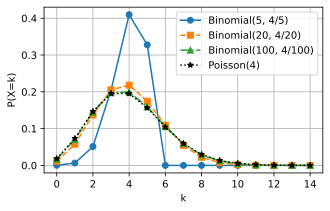

In [4]:
ns, ks = (5, 20, 100), np.arange(15)
d2l.plot(ks, [binomial_pmf(n, 4 / n, 14) for n in ns] + [poisson_pmf(4.0, 14)],
         xlabel='k', ylabel='P(X=k)', fmts=('o-', 's--', '^-.', 'k*:'),
         legend=[f'Binomial({n}, 4/{n})' for n in ns] + ['Poisson(4)'],
         figsize=(5, 3))
for n in (20, 100, 1000):
    tv = 0.5 * np.abs(binomial_pmf(n, 4 / n, 60) - poisson_pmf(4.0, 60)).sum()
    print(f'n = {n:4d}: total-variation distance {tv:.3f}')

At $n=5$, the binomial cannot exceed five requests and its peak sits noticeably
too high. By $n=100$, the two pmfs are visually indistinguishable. The
total-variation distance drops from $0.056$ at $n=20$ to $0.010$ at $n=100$ and
$0.001$ at $n=1000$, shrinking roughly in proportion to $1/n$.

### Categorical and Multinomial

A classifier with $K$ classes, or a language model predicting the next token
from a vocabulary, chooses among more than two outcomes. The categorical
distribution is simply a $K$-sided coin.

A *categorical* random variable takes values in $\{1,\dots,K\}$ with
probabilities specified by a vector $\mathbf p=(p_1,\dots,p_K)$, where
$p_k\ge0$ and $\sum_k p_k=1$:

$$
P(X=k) = p_k .
$$

When $K=2$, this reduces to the Bernoulli distribution. In neural networks, we
rarely predict probabilities directly; instead, the network outputs
unconstrained real scores $z_1,\dots,z_K$ called *logits*, and converts them
into a categorical distribution via the *softmax* function:

$$
p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}} .
$$

Exponentiating guarantees that every entry is positive, and dividing by the
sum ensures they add to one. For example, the logits $\mathbf z=(2,1,0.1,-1)$
produce $\mathbf p\approx(0.638,0.235,0.095,0.032)$. Writing the true class as
a one-hot vector $\mathbf y$, the negative log-probability assigned to the
observed label is $-\log p_y=-\sum_k y_k\log p_k$, which is the *softmax
cross-entropy* loss of that section. Just as
binary cross-entropy fits a Bernoulli distribution, softmax cross-entropy fits
a categorical distribution to each label.

**The discrete uniform.** The simplest categorical distribution gives every
outcome the same probability. On $\{1,\dots,n\}$ with $p_k=1/n$, this is the
*discrete uniform* distribution $\mathrm{Unif}\{1,\dots,n\}$: a fair die, or an
index drawn uniformly at random. Its mean and variance follow from the standard
sums $\sum_{i=1}^n i=\tfrac{n(n+1)}2$ and
$\sum_{i=1}^n i^2=\tfrac{n(n+1)(2n+1)}6$:

$$
\begin{aligned}
\mathbb{E}[X] &= \frac1n\sum_{i=1}^n i = \frac{n+1}{2}, \\
\textrm{Var}(X) &= \frac{(n+1)(2n+1)}{6} - \frac{(n+1)^2}{4} \\
&= \frac{(n+1)\bigl(2(2n+1)-3(n+1)\bigr)}{12} = \frac{n^2-1}{12}.
\end{aligned}
$$

The mean sits right at the midpoint, while the variance grows like $n^2$
because the outcomes span a range of length $n-1$. For a fair six-sided die,
the mean is $3.5$ and the variance is $35/12\approx2.92$.

**The multinomial.** Just as repeating a Bernoulli trial $n$ times yields the
binomial, drawing $n$ independent samples from a categorical distribution and
tallying how often each class appears yields the *multinomial* distribution.
The count vector $\mathbf x=(x_1,\dots,x_K)$, constrained by $\sum_k x_k=n$,
has pmf

$$
P(\mathbf x) = \frac{n!}{x_1!\cdots x_K!}\,\prod_{k=1}^{K} p_k^{x_k}.
$$

As with the binomial, the leading multinomial coefficient counts the number of
orderings of $n$ draws that yield the counts $\mathbf x$, and the product gives
the probability of any single ordering. For $K=2$, the coefficient reduces to
$\binom{n}{x_1}$ and we recover the binomial ($13!/(9!\,4!)=715$). Looking at
any single class $k$ in isolation, each draw either lands in class $k$ or does
not, so $x_k\sim\mathrm{Binomial}(n,p_k)$ with $\mathbb{E}[x_k]=np_k$ and
$\textrm{Var}(x_k)=np_k(1-p_k)$. Across all classes jointly, the count vector
has mean $n\mathbf p$ and covariance matrix
$n\bigl(\operatorname{diag}(\mathbf p)-\mathbf p\mathbf p^\top\bigr)$, derived
in exercise 7. Notice that
every off-diagonal entry is negative: because the total number of draws $n$ is
fixed, extra counts in one class must come at the expense of the others. When
$n=1$, the count vector is simply the one-hot encoding of a single categorical
draw.

Let us compute the softmax probabilities for our example logits and draw
$10{,}000$ samples from the resulting categorical distribution to check the
empirical frequencies.

In [5]:
z = np.array([2.0, 1.0, 0.1, -1.0])          # logits for K = 4 classes
p_cat = np.exp(z) / np.exp(z).sum()           # softmax
draws = rng.choice(4, size=10000, p=p_cat)
print('softmax p   =', p_cat.round(3))
print('frequencies =', (np.bincount(draws, minlength=4) / 10000).round(3))

softmax p   = [0.638 0.235 0.095 0.032]
frequencies = [0.638 0.24  0.091 0.031]


The empirical frequencies match $\mathbf p$ to within about a percentage point.

## Continuous Distributions

A continuous random variable is described by a probability density function
$p(x)\ge0$ satisfying $\int p(x)\,dx=1$. Probabilities are areas under the
density curve, and expectations and variances are integrals, as in
that section. We begin with the exponential distribution,
because the Poisson process has already handed it to us.

### Exponential

Let us return to our web server. The Poisson distribution tells us how many
requests arrive in a minute. An engineer configuring a timeout asks a closely
related question about the same stream of traffic: how long will we wait until
the next request arrives?

Remarkably, the two questions share an answer. Waiting more than one minute for
the next request is the exact same event as observing zero requests during that
minute, so $P(\text{wait}>1)=P(N=0)=e^{-4}\approx0.018$, the Poisson
probability we already computed. the figure
illustrates how both distributions describe a single stream of events.

![One stream of requests arriving at an average rate of four per minute, viewed two ways. (a) Event times over three minutes: the unit windows contain $N = 4$, $2$, and $5$ requests, while $T_1$, $T_2$, and $T_3$ are the first three waiting times. (b) The number of requests in a minute follows Poisson$(4)$, so a silent minute has probability $e^{-4}\approx0.018$. (c) The probability that a wait exceeds $t$ minutes is $e^{-4t}$, a straight line on a logarithmic axis; waiting longer than a minute and seeing a silent minute are the same event.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-poisson-timeline.svg)

The exact same reasoning applies to any duration $t\ge0$. In a Poisson process
with rate $\lambda$, the waiting time $T$ from time $0$ until the first event
exceeds $t$ if and only if the interval $[0,t]$ contains zero events. Since the
count in $[0,t]$ follows $\mathrm{Poisson}(\lambda t)$, we obtain

$$
P(T>t) = P\bigl(N(t)=0\bigr) = e^{-\lambda t}, \qquad t\ge0 .
$$

The cumulative distribution function is therefore $F(t)=1-e^{-\lambda t}$, and
differentiating it gives the density of the *exponential* distribution with
rate $\lambda>0$:

$$
p(t) = \lambda e^{-\lambda t}\quad (t\ge0),
\qquad
p(t) = 0\quad (t<0),
\qquad
F(t) = 1 - e^{-\lambda t},
\qquad T\sim\mathrm{Exp}(\lambda).
$$

In other words, the density measures the rate at which the probability of an
empty window decays. Because future slices of a Poisson process after any
arrival are fresh independent trials, the waiting time after each event has the
same distribution: the gaps between consecutive arrivals are independent
$\mathrm{Exp}(\lambda)$ random variables.

**Mean and variance.** Two quick integrations by parts give the moments. Using
$\int_0^\infty u\,e^{-u}\,du=[-ue^{-u}]_0^\infty+\int_0^\infty e^{-u}\,du=1$
and
$\int_0^\infty u^2e^{-u}\,du=[-u^2e^{-u}]_0^\infty+2\int_0^\infty u\,e^{-u}\,du=2$,
the substitution $u=\lambda t$ yields

$$
\mathbb{E}[T] = \int_0^\infty t\,\lambda e^{-\lambda t}\,dt = \frac1\lambda,
\qquad
\mathbb{E}[T^2] = \frac{2}{\lambda^2},
\qquad
\textrm{Var}(T) = \frac{2}{\lambda^2}-\frac1{\lambda^2} = \frac1{\lambda^2}.
$$

As intuition demands, a higher arrival rate means shorter waits. At four
requests per minute, the average wait is $\tfrac14$ minute, or 15 seconds. The
median $m$ solves $F(m)=\tfrac12$, giving $m=\log2/\lambda\approx10.4$ seconds:
half of all waits last less than about 10 seconds even though the mean is 15.
Because the density peaks at $t=0$ and trails off in a long right tail, the
mean is pulled well above the median.

**Memorylessness.** Suppose you have already waited $s$ minutes without seeing
a request. What is the probability that you will have to wait at least $t$
minutes more?

$$
P(T>s+t \mid T>s)
= \frac{P(T>s+t)}{P(T>s)}
= \frac{e^{-\lambda(s+t)}}{e^{-\lambda s}}
= e^{-\lambda t}
= P(T>t).
$$

Time already spent waiting tells you nothing at all about the remaining wait.
Among all continuous distributions on $(0,\infty)$, the exponential is the only
one with this *memoryless* property, as exercise
2 proves. Memorylessness also
marks the boundary of where the model applies. A light bulb whose filament
wears down with use is more likely to fail in the next hour the older it gets,
so its lifetime is not exponential.

**The Gamma distribution.** What if we ask for the time $T_k$ until the $k$-th
request arrives? Since $T_k$ is the sum of $k$ independent exponential waits,
linearity of expectation and independence immediately give its mean $k/\lambda$
and variance $k/\lambda^2$. Its density also drops straight out of the Poisson
process: the $k$-th arrival occurs after time $t$ if and only if at most $k-1$
events occur in $[0,t]$, so

$$
P(T_k>t) = P\bigl(N(t)\le k-1\bigr) = \sum_{j=0}^{k-1} e^{-\lambda t}\frac{(\lambda t)^j}{j!}.
$$

When we differentiate the $j$-th term with respect to $t$, the product rule
produces
$-\lambda e^{-\lambda t}\frac{(\lambda t)^j}{j!}+\lambda e^{-\lambda t}\frac{(\lambda t)^{j-1}}{(j-1)!}$.
Notice how the second piece cancels the first piece of the previous term. The
entire sum telescopes, leaving only the first piece of the final ($j=k-1$)
term:

$$
p(t) = -\frac{d}{dt}P(T_k>t) = \frac{\lambda^k\,t^{k-1}e^{-\lambda t}}{(k-1)!},
\qquad t>0 .
$$

For $k=1$, we recover the exponential density. To extend this family beyond
integer $k$, we replace $(k-1)!$ with the *Gamma function*
$\Gamma(z)=\int_0^\infty u^{z-1}e^{-u}\,du$ for $z>0$. Integration by parts
shows that $\Gamma(z+1)=z\,\Gamma(z)$, and since $\Gamma(1)=1$, we have
$\Gamma(n+1)=n!$ for every nonnegative integer $n$. This defines the *Gamma
distribution* with shape $\alpha>0$ and rate $\beta>0$:

$$
p(t) = \frac{\beta^{\alpha}\,t^{\alpha-1}e^{-\beta t}}{\Gamma(\alpha)},
\qquad t>0,
\qquad T\sim\mathrm{Gamma}(\alpha,\beta).
$$

Substituting $u=\beta t$ reduces the integral of $p(t)$ to
$\Gamma(\alpha)/\Gamma(\alpha)=1$, and the same substitution yields
$\mathbb{E}[T]=\Gamma(\alpha+1)/(\beta\,\Gamma(\alpha))=\alpha/\beta$ and
$\textrm{Var}(T)=\alpha/\beta^2$. When $\alpha=k$ and $\beta=\lambda$, these
match the moments of the $k$-th waiting time. For our web server, the 4th
request arrives after an average of $1$ minute with standard deviation $0.5$
minutes, and $P(T_4>1)=P(N(1)\le3)\approx0.43$: in 43% of minutes, fewer than
four requests arrive, even though four is the average.

**Sampling.** Recall from that section that the
inverse-transform method converts a uniform draw $U$ into a sample from any
continuous distribution with an invertible c.d.f. $F$ by computing
$X=F^{-1}(U)$. For the exponential distribution, $F^{-1}(q)=-\log(1-q)/\lambda$,
so $T=-\log(1-U)/\lambda$. Although $1-U$ and $U$ have the same distribution,
writing $1-U$ matters in practice: random number generators return values in
$[0,1)$, where $U=0$ can occur and $-\log U$ would overflow to infinity.

If our connection between the Poisson process and the exponential distribution
is airtight, we should be able to run the construction backwards: generate
independent exponential gaps, accumulate them into arrival times, and recover
Poisson counts per minute. Let us test this with $60{,}000$ gaps at rate $4$
and inspect the first $10{,}000$ minutes.

In [6]:
lam = 4.0                                       # requests per minute
gaps = -np.log(1 - rng.random(60000)) / lam     # inverse transform: Exp(lam)
times = np.cumsum(gaps)                         # event times, about 15,000 min
counts = np.bincount(times[times < 10000].astype(int), minlength=10000)
print(f'requests per minute: mean {counts.mean():.2f}, variance {counts.var(ddof=1):.2f}')
print(f'silent minutes {np.mean(counts == 0):.4f},   waits over 1 min '
      f'{np.mean(gaps > 1):.4f},   e^-4 = {math.exp(-4):.4f}')
print(f'mean wait {gaps.mean():.3f} min,   minutes with at most 3 requests '
      f'{np.mean(counts <= 3):.3f}')

requests per minute: mean 4.00, variance 4.05
silent minutes 0.0196,   waits over 1 min 0.0187,   e^-4 = 0.0183
mean wait 0.250 min,   minutes with at most 3 requests 0.435


The simulated counts indeed have mean and variance close to $4$. Both the
fraction of silent minutes and the fraction of waits longer than a minute sit
right around $e^{-4}$, and the fraction of minutes with at most three requests
matches the Gamma prediction $P(T_4>1)\approx0.43$. Generating exponential gaps
reproduces Poisson counts.

### Uniform

Every sampler in this section starts from the same raw material: a number drawn
uniformly at random from $[0,1)$. That distribution, generalized to any finite
interval, is the continuous uniform distribution.

The *uniform* distribution $U(a,b)$ on an interval $[a,b]$ with $a<b$ has a
constant density, fixed by the requirement that it integrate to one:

$$
p(x) = \begin{cases}\frac{1}{b-a} & x\in[a,b],\\ 0 & \text{otherwise.}\end{cases}
$$

Every subinterval of equal length receives the same probability, namely its
length divided by $b-a$. Both moments follow by direct integration. For the
variance, it is cleaner to center the interval at its midpoint so that it runs
from $-c$ to $c$ with $c=\tfrac{b-a}2$:

$$
\mathbb{E}[X] = \int_a^b \frac{x}{b-a}\,dx = \frac{b^2-a^2}{2(b-a)} = \frac{a+b}{2},
\qquad
\textrm{Var}(X) = \int_{-c}^{c} \frac{y^2}{2c}\,dy = \frac{c^2}{3} = \frac{(b-a)^2}{12}.
$$

In particular, $U(0,1)$ has mean $\tfrac12$ and variance $\tfrac1{12}$, while
$U(-\sqrt3,\sqrt3)$ has variance $(2\sqrt3)^2/12=1$. Notice how this formula is
the continuous limit of the discrete uniform: $n$ equally likely points spaced
$h$ apart have variance $h^2(n^2-1)/12$, which converges to $(b-a)^2/12$ as
the points fill $[a,b]$ with $nh=b-a$. Through the inverse transform, $U(0,1)$
can be reshaped into any continuous distribution, as we just did for the
exponential. Visually, the uniform has flat density, hard edges, and no tails
at all, so it looks nothing like a Gaussian. That makes it the ideal test case
when we watch the central limit theorem turn sums of uniforms into a bell curve
below.

### Gaussian

Our successive ratio computes any binomial probability to high precision, yet
it does not tell us what the distribution looks like as a whole. Is there a
simple closed-form expression for its shape near the peak? Remarkably, there
is, and only the mean and variance of the coin appear in it. This brings us to
the most important distribution in probability and machine learning.

**The log-ratio near the mean.** Let $q=1-p$, and measure the count by its
distance $x$ from the mean, so $k=np+x$. Substituting this into the binomial's
successive ratio gives

$$
\frac{P(X=k+1)}{P(X=k)} = \frac{(n-k)\,p}{(k+1)\,q}
= \frac{(nq-x)\,p}{(np+x+1)\,q}
= \frac{1-x/(nq)}{1+(x+1)/(np)} .
$$

When $x$ is on the order of the standard deviation $\sqrt{npq}$ and $n$ is
large, both $x/(nq)$ and $(x+1)/(np)$ are small. Taking the logarithm and
applying the linear approximation $\log(1+\epsilon)\approx\epsilon$ yields

$$
\log\frac{P(X=k+1)}{P(X=k)} \approx -\frac{x}{nq}-\frac{x+1}{np}
= -\frac{x}{npq}-\frac{1}{np},
$$

where we combined the fractions using $\frac1{nq}+\frac1{np}=\frac{p+q}{npq}=\frac{1}{npq}$.
To leading order, each step from $\log P(X=k)$ to $\log P(X=k+1)$ changes
linearly with the distance $x$ from the mean, at slope $-1/(npq)$. What kind
of function has a linearly changing step? A parabola. Indeed, the parabola
$-x^2/(2npq)$ changes by

$$
-\frac{(x+1)^2-x^2}{2npq} = -\frac{x}{npq}-\frac{1}{2npq}
$$

as $x$ increases by $1$. This matches the step of $\log P$ up to a tiny
constant $(p-q)/(2npq)$, which vanishes altogether for a fair coin and in
general accumulates to only $O(1/\sqrt n)$ over the $\sqrt{npq}$ steps around
the peak. We conclude that

$$
\log P(X=np+x) \approx C-\frac{x^2}{2npq}
$$

for some constant $C$, at every count $k=np+x$ within a few standard deviations
of the mean, regardless of whether $np$ is an integer (for our 13 flips,
$np=6.5$). Exponentiating both sides, we see that near its peak the binomial
takes the shape of a bell curve, $e^{C}e^{-x^2/(2npq)}$, centered at the mean
with width set by its standard deviation $\sqrt{npq}$. Because we dropped
higher-order remainders informally, this is a derivation sketch rather than a
rigorous proof; the rigorous version is the *de Moivre–Laplace theorem*, the
earliest form of the central limit theorem.

**The normalizer.** To determine the constant $C$, we use the fact that the
probabilities must sum to one. Since integer counts are spaced $1$ apart, the
sum of the bell over all $k$ is closely approximated by the integral
$e^C\int_{-\infty}^\infty e^{-x^2/(2npq)}\,dx$. Everything therefore reduces to
evaluating $I=\int_{-\infty}^\infty e^{-x^2/2}\,dx$. At first glance this
integral looks hopeless, because $e^{-x^2/2}$ has no elementary antiderivative.
The classic trick is to compute $I^2$ instead: as a double integral over the
plane, switching to polar coordinates $x=r\cos\theta$, $y=r\sin\theta$ with
area element $dx\,dy=r\,dr\,d\theta$ makes the integrand elementary:

$$
\begin{aligned}
I^2 &= \int_{-\infty}^{\infty}\!\int_{-\infty}^{\infty} e^{-(x^2+y^2)/2}\,dx\,dy
= \int_0^{2\pi}\!\!\int_0^\infty e^{-r^2/2}\,r\,dr\,d\theta \\
&= 2\pi\,\Bigl[-e^{-r^2/2}\Bigr]_0^\infty = 2\pi .
\end{aligned}
$$

Hence $I=\sqrt{2\pi}$. The extra factor of $r$ from the polar Jacobian gives
$r\,e^{-r^2/2}$ the elementary antiderivative $-e^{-r^2/2}$, which
$e^{-x^2/2}$ alone lacks. Changing variables via $x=\sqrt{npq}\,u$ then gives
$\int_{-\infty}^\infty e^{-x^2/(2npq)}\,dx=\sqrt{2\pi npq}$, fixing
$e^C=1/\sqrt{2\pi npq}$ and leaving

$$
P(X=np+x)\approx \frac{1}{\sqrt{2\pi npq}}\,e^{-x^2/(2npq)} .
$$

Let us test this on our 13 fair flips, where $npq=3.25$ and $k=9$ corresponds
to $x=2.5$: the bell gives $e^{-2.5^2/6.5}/\sqrt{2\pi\cdot3.25}\approx0.0846$,
surprisingly close to the exact value $0.0873$ even for so small an $n$. Below,
we measure how quickly the bell approximation sharpens as $n$ grows.

In [7]:
for n in (13, 100, 1000):
    k = np.arange(n + 1)
    bell = np.exp(-(k - n / 2)**2 / (n / 2)) / np.sqrt(np.pi * n / 2)
    exact = binomial_pmf(n, 0.5, n)
    peak = n // 2
    print(f'n = {n:4d}: relative error at the peak {abs(bell[peak] / exact[peak] - 1):.2%}')
print(f'n = 13, k = 9: bell {np.exp(-2.5**2 / 6.5) / np.sqrt(np.pi * 6.5):.4f},'
      f' exact {binomial_pmf(13, 0.5, 13)[9]:.4f}')

n =   13: relative error at the peak 1.66%
n =  100: relative error at the peak 0.25%
n = 1000: relative error at the peak 0.03%
n = 13, k = 9: bell 0.0846, exact 0.0873


At $n=13$ and $k=9$, the bell is only about 3% low, and its relative error at
the peak falls from $1.7\%$ at $n=13$ to $0.25\%$ at $n=100$ and $0.03\%$ at
$n=1000$, shrinking roughly like $1/n$.

**The standard Gaussian.** The parabolic exponent suggests a natural rescaling.
The standardized count $Y^{(n)}=(X-np)/\sqrt{npq}$ has mean $0$ and variance
$1$ for every $n$, and its possible values are spaced $1/\sqrt{npq}$ apart.
In these units, our bell approximation reads
$P(X=k)\approx\phi(y)/\sqrt{npq}$ at $y=(k-np)/\sqrt{npq}$: a smooth density
$\phi(y)$ multiplied by the grid spacing, where

$$
\phi(y) = \frac{1}{\sqrt{2\pi}}\,e^{-y^2/2}.
$$

This is the density of the *standard Gaussian* $\mathcal N(0,1)$, the limiting
distribution of the standardized binomial. It integrates to one because
$I=\sqrt{2\pi}$, and its mean is $0$ by symmetry around the origin. For the
variance, integrating by parts with $u=x$ and $dv=x\,e^{-x^2/2}\,dx$ gives

$$
\int_{-\infty}^{\infty} x^2\,\frac{e^{-x^2/2}}{\sqrt{2\pi}}\,dx
= \frac{1}{\sqrt{2\pi}}\Bigl(\bigl[-x\,e^{-x^2/2}\bigr]_{-\infty}^{\infty}
+ \int_{-\infty}^{\infty} e^{-x^2/2}\,dx\Bigr) = 0 + 1 = 1 .
$$

Thus the standard Gaussian has variance $1$. Shifting $Y$ by $\mu$ and scaling
by $\sigma>0$ produces $X=\mu+\sigma Y$. By the change-of-variables formula of
that section, its density is
$\phi((x-\mu)/\sigma)/\sigma$, which defines the general *Gaussian* (or normal)
distribution:

$$
p(x) = \frac{1}{\sqrt{2\pi\sigma^2}}\,\exp\!\Bigl(-\frac{(x-\mu)^2}{2\sigma^2}\Bigr),
\qquad X\sim\mathcal N(\mu,\sigma^2).
$$

Because $X=\mu+\sigma Y$, its mean is $\mu$ and its variance is $\sigma^2$: the
two parameters are directly the first two moments, with $\sigma$ controlling
the width of the bell.

**The central limit theorem.** Looking back at our derivation, surprisingly
little about coin flips entered the final shape beyond their mean and variance.
In fact, the general theorem needs nothing else. Let $X_1,X_2,\dots$ be
independent and identically distributed random variables with mean $\mu$ and
finite variance $0<\sigma^2<\infty$, and let $S_n=\sum_{i=1}^n X_i$. Then for
every real number $y$,

$$
\lim_{n\to\infty} P\Bigl(\frac{S_n-n\mu}{\sigma\sqrt n}\le y\Bigr) = \Phi(y)
= \int_{-\infty}^{y}\phi(u)\,du .
$$

In words, the standardized sum of many independent copies of *any* distribution
with finite variance converges to the standard Gaussian. For Bernoulli
summands, this is the de Moivre–Laplace theorem; for the general proof, see
[@Wasserman.2013]. Only the mean and variance of the individual summands
survive in the limit, which is why quantities built from many small independent
effects, such as sensor or measurement noise, so reliably look Gaussian.

**Sums of uniforms.** The central limit theorem is even more striking when
watched in action. Let us start from $U(0,1)$, which is completely flat with
sharp edges and zero tails, sum $n$ independent draws, standardize by the mean
$n/2$ and standard deviation $\sqrt{n/12}$, and compare the resulting
histograms with $\phi$.

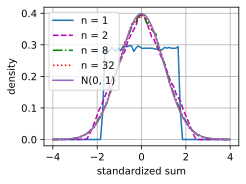

In [8]:
ns, x = (1, 2, 8, 32), np.arange(-4, 4, 0.01)
curves = []
for n in ns:                                   # standardized sums of n uniforms
    s = (rng.random((100000, n)).sum(1) - n / 2) / np.sqrt(n / 12)
    hist, edges = np.histogram(s, bins=80, range=(-4, 4), density=True)
    curves.append(np.interp(x, (edges[:-1] + edges[1:]) / 2, hist))
curves.append(np.exp(-x**2 / 2) / np.sqrt(2 * np.pi))     # N(0, 1) density
d2l.plot(x, curves, xlabel='standardized sum', ylabel='density',
         legend=[f'n = {n}' for n in ns] + ['N(0, 1)'])

At $n=1$ we see the flat plateau of the uniform, and at $n=2$ a sharp triangle.
Already by $n=8$, the histogram closely tracks the Gaussian bell, and by $n=32$
the two curves are indistinguishable at the resolution of the plot.

The finite-variance assumption, however, cannot be dropped. As we saw in
that section, averages of Cauchy draws never settle down
no matter how many samples we average, whereas the average of $n$ standard
Gaussians follows $\mathcal N(0,1/n)$ and concentrates tightly around zero.

**Gaussian noise and squared error.** When a regression network predicts
$\hat y$ and models the observed label as $y\sim\mathcal N(\hat y,\sigma^2)$,
the negative log-probability it assigns to $y$ is
$-\log p(y)=(y-\hat y)^2/(2\sigma^2)+\tfrac12\log(2\pi\sigma^2)$. Up to a
positive scale factor and an additive constant, this is the squared error loss
(that section).

### Laplace

Because squared error grows quadratically, a residual of $10$ is penalized a
hundred times more heavily than a residual of $1$, allowing a handful of
outliers to pull a fit far off course. A loss that grows only linearly, the
absolute error, corresponds to a heavier-tailed noise distribution
(that section).

To construct it, take a fair random sign $S$ with
$P(S=1)=P(S=-1)=\tfrac12$, together with an independent exponential variable
$E$ of mean $b>0$ (rate $1/b$), and set $X=\mu+SE$. Whenever $S=1$, $X$ lies
above $\mu$ with $X-\mu=E$, so for $x>\mu$ the density is
$\tfrac12\cdot\tfrac1b e^{-(x-\mu)/b}$. By symmetry, the same expression holds
below $\mu$ with $x-\mu$ replaced by $|x-\mu|$. This gives the *Laplace*
distribution:

$$
p(x) = \frac{1}{2b}\,e^{-|x-\mu|/b},
\qquad X\sim\mathrm{Laplace}(\mu,b).
$$

Each half of the distribution carries half the mass of an exponential. The
density is symmetric around $\mu$, comes to a sharp peak there, and decays
exponentially on both sides.

**Mean and variance.** Both moments follow immediately from $X=\mu+SE$. By
independence, $\mathbb{E}[SE]=\mathbb{E}[S]\,\mathbb{E}[E]=0$, so
$\mathbb{E}[X]=\mu$. And since $S^2=1$ always, the variance is simply the
exponential's second moment, $2/\lambda^2$ with $\lambda=1/b$:

$$
\textrm{Var}(X) = \mathbb{E}\bigl[S^2E^2\bigr] = \mathbb{E}[E^2] = 2b^2 .
$$

**Laplace noise and absolute error.** If a regression network models the label
as $y\sim\mathrm{Laplace}(\hat y,b)$, its negative log-probability is
$-\log p(y)=|y-\hat y|/b+\log 2b$, which is the absolute error up to scaling
and a constant. Used as a prior over model weights, the Laplace density yields
the $\ell_1$ penalty $\|\mathbf w\|_1$ of the LASSO [@Tibshirani.1996].
Moreover, when fitting a location parameter $\mu$ to data $x_1,\dots,x_m$,
maximizing the Laplace probability minimizes $\sum_i|x_i-\mu|$, which is
achieved at the sample median. Whereas a single corrupted point can drag the
sample mean arbitrarily far, it shifts the median by at most one rank.

**Tails.** the figure compares the uniform,
Gaussian, and Laplace densities scaled to have the same variance. At matched
variance $\sigma^2=2b^2$, the probability that a Laplace variable lands more
than three standard deviations from its center is
$P(|X-\mu|>3\sigma)=e^{-3\sigma/b}=e^{-3\sqrt2}\approx0.014$, compared with
$0.0027$ for the Gaussian: roughly five times as much tail mass.

![Three densities with unit variance: the uniform on $[-\sqrt{3},\sqrt{3}]$, the standard Gaussian, and the Laplace with $b=1/\sqrt{2}$. (a) Densities on a linear scale. (b) The same densities on a logarithmic scale, where the Gaussian is a parabola, the Laplace forms two straight lines, and the uniform is a flat plateau ending at $\pm\sqrt{3}$. Beyond three standard deviations, the Laplace carries about five times the tail probability of the Gaussian.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-continuous-pdfs.svg)

Let us verify this tail comparison directly by sampling the Laplace from its
construction (a random sign times an exponential) and counting how often draws
exceed three standard deviations.

In [9]:
b, m = 1.0, 200000
lap = rng.choice([-1.0, 1.0], m) * rng.exponential(b, m)   # S * E
sigma = math.sqrt(2) * b                                    # matched sd
gau = rng.normal(0.0, sigma, m)
print(f'sample variances: Laplace {lap.var(ddof=1):.2f}, '
      f'Gaussian {gau.var(ddof=1):.2f}   (2b^2 = 2)')
print(f'P(|X| > 3 sd): Laplace {np.mean(np.abs(lap) > 3 * sigma):.4f}, '
      f'Gaussian {np.mean(np.abs(gau) > 3 * sigma):.4f}')

sample variances: Laplace 2.01, Gaussian 2.00   (2b^2 = 2)
P(|X| > 3 sd): Laplace 0.0144, Gaussian 0.0026


Both sample variances land right around $2$, while the tail fractions beyond
three standard deviations come out near $0.014$ and $0.003$.

## The Multivariate Gaussian

In deep learning, random quantities are rarely scalars: image noise, latent
representations in a generative model, and predictions across a batch of inputs
are all vectors whose coordinates interact. The multivariate Gaussian is the
one distribution over correlated vectors that remains analytically tractable
under nearly every operation we care about. As our running example, consider a
pair of coordinates with variance $2$ each and covariance $1$:

$$
\boldsymbol\Sigma = \begin{pmatrix}2&1\\1&2\end{pmatrix}.
$$

### Contours and Eigenvectors

The *multivariate Gaussian* $\mathcal N(\boldsymbol\mu,\boldsymbol\Sigma)$ on
$\mathbb R^d$ is parameterized by a mean vector $\boldsymbol\mu$ and a
symmetric, positive definite covariance matrix $\boldsymbol\Sigma$. Its density
is

$$
p(\mathbf x) = \frac{1}{(2\pi)^{d/2}|\boldsymbol\Sigma|^{1/2}}
\exp\!\Bigl(-\tfrac12(\mathbf x-\boldsymbol\mu)^\top\boldsymbol\Sigma^{-1}(\mathbf x-\boldsymbol\mu)\Bigr),
$$

where $|\boldsymbol\Sigma|$ denotes the determinant of $\boldsymbol\Sigma$.
When $d=1$, this reduces to the equation. Because $\mathbf x$
enters the density solely through the quadratic form in the exponent, the
density is constant on the level sets where that quadratic form is constant.
What geometry do these contours have?

**The running example by hand.** Take $\boldsymbol\mu=\mathbf 0$ and rotate
the coordinate axes by $45^\circ$ into the sum and difference coordinates
$u=(x_1+x_2)/\sqrt2$ and $w=(x_1-x_2)/\sqrt2$. Their variances and covariance
follow directly from the entries of $\boldsymbol\Sigma$:

$$
\textrm{Var}(u) = \frac{2+2+2\cdot1}{2} = 3,
\qquad
\textrm{Var}(w) = \frac{2+2-2\cdot1}{2} = 1,
\qquad
\textrm{Cov}(u,w) = \frac{2-2}{2} = 0 .
$$

In these rotated coordinates, the covariance matrix is diagonal. The new axes
are simply the eigenvectors $\mathbf v_1=(1,1)/\sqrt2$ and
$\mathbf v_2=(1,-1)/\sqrt2$ of $\boldsymbol\Sigma$, with eigenvalues
$\gamma_1=3$ and $\gamma_2=1$ (indeed,
$\boldsymbol\Sigma\mathbf v_1=(3,3)/\sqrt2=3\mathbf v_1$).

**The general case.** By the spectral theorem, every symmetric matrix admits an
orthonormal basis of eigenvectors,
$\boldsymbol\Sigma=\mathbf V\operatorname{diag}(\gamma_1,\dots,\gamma_d)\mathbf V^\top$
with $\mathbf V^\top\mathbf V=\mathbf I$, and positive definiteness ensures
that every eigenvalue satisfies $\gamma_i>0$. Passing to the eigen-coordinates
$\mathbf u=\mathbf V^\top(\mathbf x-\boldsymbol\mu)$ turns the quadratic form
into a simple weighted sum of squares:

$$
(\mathbf x-\boldsymbol\mu)^\top\boldsymbol\Sigma^{-1}(\mathbf x-\boldsymbol\mu)
= \mathbf u^\top\operatorname{diag}(\gamma_1^{-1},\dots,\gamma_d^{-1})\,\mathbf u
= \sum_{i=1}^d \frac{u_i^2}{\gamma_i}.
$$

The level set where this sum equals $r^2$ is an ellipsoid aligned with the
eigenvectors $\mathbf v_i$, with half-axis lengths $r\sqrt{\gamma_i}$. Thus the
contours of any multivariate Gaussian are ellipsoids whose principal axes are
the eigenvectors of $\boldsymbol\Sigma$, stretched in proportion to the
standard deviations $\sqrt{\gamma_i}$. For our running example, they are
ellipses tilted at $45^\circ$ with axis ratio $\sqrt3:1$
(the figure, left). Because
$|\boldsymbol\Sigma|=\prod_i\gamma_i$, the density also splits in $\mathbf u$
into a product of $d$ one-dimensional Gaussians: along the eigenvector
directions, the coordinates are independent with variances $\gamma_i$. In the
special case $\boldsymbol\Sigma=\sigma^2\mathbf I$, the contours are spheres
and the original coordinates are already independent.

![The running bivariate Gaussian with covariance $\boldsymbol{\Sigma}$ having rows $(2, 1)$ and $(1, 2)$. (a) 400 samples and three density contours on which the quadratic form in the exponent equals $1$, $4$, and $9$. The ellipse axes lie along the eigenvectors of $\boldsymbol{\Sigma}$ with half-lengths proportional to $\sqrt{\gamma_1} = \sqrt{3}$ and $\sqrt{\gamma_2} = 1$; the arrows $\mathbf{v}_1$ and $\mathbf{v}_2$ reach the middle contour. (b) Observing $x_2 = 2$ slices the density along the dashed line, yielding the conditional density $\mathcal{N}(1, \frac{3}{2})$ for $x_1$. Across all slices, the conditional means lie along $x_1 = x_2/2$, and the conditional variance stays fixed at $3/2$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-mvn-contours.svg)

One caveat is worth flagging early. In high dimensions, our low-dimensional
intuition of a bell concentrated near the mean can mislead: a standard Gaussian
vector in $\mathbb R^d$ almost always has norm close to $\sqrt d$, and two
independent draws are nearly orthogonal. We prove both facts in
that section.

### Linear Maps and Sampling

In practice, we routinely build new Gaussian vectors from existing ones by
mixing coordinates or projecting onto a subspace. Both are linear maps, and a
key reason Gaussians are so convenient is that linear maps preserve
Gaussianity. We prove this first for invertible square matrices, which is all
we need for sampling; rectangular projections will follow in the next
subsection once we show that any subvector of a Gaussian is itself Gaussian.

**Proposition (invertible linear maps).** Let
$\mathbf x\sim\mathcal N(\boldsymbol\mu,\boldsymbol\Sigma)$ in $\mathbb R^d$,
let $\mathbf A$ be an invertible $d\times d$ matrix, and let
$\mathbf b\in\mathbb R^d$. Then

$$
\mathbf A\mathbf x+\mathbf b\sim\mathcal N\bigl(\mathbf A\boldsymbol\mu+\mathbf b,\;\mathbf A\boldsymbol\Sigma\mathbf A^\top\bigr).
$$

**Proof.** By linearity of expectation, the stated mean and covariance hold
for any distribution with finite second moments:
$\mathbb{E}[(\mathbf A\mathbf x-\mathbf A\boldsymbol\mu)(\mathbf A\mathbf x-\mathbf A\boldsymbol\mu)^\top]$
equals $\mathbf A\,\mathbb{E}[(\mathbf x-\boldsymbol\mu)(\mathbf x-\boldsymbol\mu)^\top]\,\mathbf A^\top
=\mathbf A\boldsymbol\Sigma\mathbf A^\top$. It remains only to check that the
transformed density is Gaussian. By the change-of-variables formula of
that section, the density of
$\mathbf y=\mathbf A\mathbf x+\mathbf b$ is
$p_{\mathbf y}(\mathbf y)=p_{\mathbf x}(\mathbf A^{-1}(\mathbf y-\mathbf b))/|\det\mathbf A|$.
Setting $\mathbf c=\mathbf y-\mathbf A\boldsymbol\mu-\mathbf b$, the exponent
rewrites as
$-\tfrac12\mathbf c^\top\mathbf A^{-\top}\boldsymbol\Sigma^{-1}\mathbf A^{-1}\mathbf c
=-\tfrac12\mathbf c^\top(\mathbf A\boldsymbol\Sigma\mathbf A^\top)^{-1}\mathbf c$,
while the normalizing factor satisfies
$|\det\mathbf A|\,|\boldsymbol\Sigma|^{1/2}=|\mathbf A\boldsymbol\Sigma\mathbf A^\top|^{1/2}$.
Thus $p_{\mathbf y}$ is the Gaussian density with the claimed mean and
covariance. $\blacksquare$

Invertibility is necessary here. If
$\mathbf A=\left(\begin{smallmatrix}1&1\\1&1\end{smallmatrix}\right)$, the
two output coordinates are always identical and
$\mathbf A\boldsymbol\Sigma\mathbf A^\top=\left(\begin{smallmatrix}6&6\\6&6\end{smallmatrix}\right)$
is singular. The resulting random vector lives entirely along the line
$y_1=y_2$ and has no two-dimensional density in the plane.

**Sampling by a matrix factor.** How do we draw from
$\mathcal N(\boldsymbol\mu,\boldsymbol\Sigma)$ when our random number generator
only produces independent standard normals? Stack $d$ independent draws into
$\mathbf z\sim\mathcal N(\mathbf 0,\mathbf I_d)$, whose joint density is the
product of $d$ copies of $\phi$. For any square matrix $\mathbf L$ satisfying
$\mathbf L\mathbf L^\top=\boldsymbol\Sigma$, $\mathbf L$ is necessarily
invertible (since $\boldsymbol\Sigma$ is positive definite), and our
proposition guarantees that $\mathbf x=\boldsymbol\mu+\mathbf L\mathbf z$ is
Gaussian with mean $\boldsymbol\mu$ and covariance
$\mathbf L\,\mathbf I\,\mathbf L^\top=\boldsymbol\Sigma$.

In short, multiplying by a matrix factor turns independent noise into
correlated noise. Because $\mathbf x$ is a smooth, differentiable function of
$\boldsymbol\mu$ and $\mathbf L$ for a fixed draw $\mathbf z$, this same
construction is the *reparameterization trick* that lets variational
autoencoders backpropagate through stochastic layers
(that section). The fastest factor to
compute is the *Cholesky factor*: every symmetric positive definite matrix
admits a unique decomposition $\boldsymbol\Sigma=\mathbf L\mathbf L^\top$ where
$\mathbf L$ is lower triangular with positive diagonal entries. For our running
example, matching entries of $\mathbf L\mathbf L^\top$ to $\boldsymbol\Sigma$
one by one gives $L_{11}=\sqrt2$, then $L_{21}=\Sigma_{21}/L_{11}=1/\sqrt2$,
and finally $L_{22}=\sqrt{\Sigma_{22}-L_{21}^2}=\sqrt{3/2}$; indeed,
$L_{21}^2+L_{22}^2=\tfrac12+\tfrac32=2$.

Any other square-root factor works equally well, such as the eigen-factor
$\mathbf V\operatorname{diag}(\sqrt{\gamma_1},\dots,\sqrt{\gamma_d})$.
As exercise 5 shows, any two factors of
the same $\boldsymbol\Sigma$ differ only by an orthogonal matrix. In practice,
library samplers differ: many use the Cholesky factor, whereas NumPy's
`multivariate_normal` defaults to a factor obtained from the singular value
decomposition.

Rather than calling a library sampler, let us implement the Cholesky recipe
directly so we can see the mechanism at work, and verify both the sample
covariance and its eigenvalues.

In [10]:
Sigma = np.array([[2.0, 1.0], [1.0, 2.0]])
L = np.linalg.cholesky(Sigma)                   # Sigma = L L^T
x = rng.standard_normal((400000, 2)) @ L.T      # each row is x = L z
C = np.cov(x.T)
print('L =', L.round(3).tolist())
print('sample covariance =', C.round(2).tolist())
print('its eigenvalues   =', np.linalg.eigvalsh(C).round(2))

L = [[1.414, 0.0], [0.707, 1.225]]
sample covariance = [[2.0, 1.0], [1.0, 2.0]]
its eigenvalues   = [1. 3.]


The Cholesky factor matches our hand calculation, the empirical covariance
agrees with $\boldsymbol\Sigma$ to within about $0.01$, and its eigenvalues sit
close to $1$ and $3$.

### Conditioning

Frequently we observe some coordinates of a Gaussian vector and want to infer
the rest. In our running example, if we observe $x_2=2$, where should we expect
$x_1$ to lie? Partition the vector into two blocks
$\mathbf x=(\mathbf x_1,\mathbf x_2)$ and partition its mean and covariance
conformably:

$$
\boldsymbol\mu = \begin{pmatrix}\boldsymbol\mu_1\\\boldsymbol\mu_2\end{pmatrix},
\qquad
\boldsymbol\Sigma = \begin{pmatrix}\boldsymbol\Sigma_{11} & \boldsymbol\Sigma_{12}\\
\boldsymbol\Sigma_{21} & \boldsymbol\Sigma_{22}\end{pmatrix}.
$$

The trick behind Gaussian conditioning is geometric and clean: subtract from
$\mathbf x_1$ the linear prediction of $\mathbf x_1$ based on $\mathbf x_2$.
What remains is a residual that carries zero information about $\mathbf x_2$.

**Proposition (residual and marginal).** Let
$\mathbf B=\boldsymbol\Sigma_{12}\boldsymbol\Sigma_{22}^{-1}$. Then the
residual $\mathbf r=\mathbf x_1-\mathbf B\mathbf x_2$ is independent of
$\mathbf x_2$, and the marginal distribution of the second block is
$\mathbf x_2\sim\mathcal N(\boldsymbol\mu_2,\boldsymbol\Sigma_{22})$.

**Proof.** Because $\boldsymbol\Sigma_{22}$ is a principal diagonal block of a
positive definite matrix, it is positive definite and hence invertible. By
construction, the residual is uncorrelated with $\mathbf x_2$:
$\textrm{Cov}(\mathbf r,\mathbf x_2)=\boldsymbol\Sigma_{12}-\mathbf B\boldsymbol\Sigma_{22}=\mathbf 0$.
The linear map $\mathbf x\mapsto(\mathbf r,\mathbf x_2)$ corresponds to the
square block matrix
$\left(\begin{smallmatrix}\mathbf I&-\mathbf B\\\mathbf 0&\mathbf I\end{smallmatrix}\right)$,
whose determinant is $1$, so $(\mathbf r,\mathbf x_2)$ is jointly Gaussian by
our proposition on invertible linear maps. Since its off-diagonal covariance
blocks vanish ($\textrm{Cov}(\mathbf r,\mathbf x_2)=\mathbf 0$), its covariance
matrix is block diagonal. Consequently, the inverse covariance is block
diagonal as well, the quadratic form in the exponent splits cleanly into a
function of $\mathbf r$ plus a function of $\mathbf x_2$, and the determinant
factors into the product of the two block determinants. The joint density
therefore factors into a Gaussian density in $\mathbf r$ times a Gaussian
density in $\mathbf x_2$: the two blocks are independent, and $\mathbf x_2$ has
mean $\boldsymbol\mu_2$ and covariance $\boldsymbol\Sigma_{22}$.
$\blacksquare$

The entire proof turns on choosing $\mathbf B$ to make the residual
uncorrelated with $\mathbf x_2$. As a bonus, the second claim proves that any
marginal subvector of a Gaussian vector is itself Gaussian (for the first
block, simply swap the block order, which is an invertible linear map). That
immediately settles the rectangular linear maps we postponed earlier.

**Corollary (wide matrices).** If $\mathbf A$ is an $m\times d$ matrix of full
row rank $m\le d$ and $\mathbf b\in\mathbb R^m$, then
$\mathbf A\mathbf x+\mathbf b\sim\mathcal N(\mathbf A\boldsymbol\mu+\mathbf b,\mathbf A\boldsymbol\Sigma\mathbf A^\top)$.
Indeed, we can augment $\mathbf A$ with $d-m$ additional rows to form an
invertible $d\times d$ matrix; its image of $\mathbf x$ is Gaussian, and
$\mathbf A\mathbf x+\mathbf b$ is simply the first block of that image.

Conditioning on $\mathbf x_2$ is now effortless. Because
$\mathbf x_1=\mathbf r+\mathbf B\mathbf x_2$ and $\mathbf r$ is independent of
$\mathbf x_2$, fixing $\mathbf x_2$ merely shifts the Gaussian variable
$\mathbf r$ by the known vector $\mathbf B\mathbf x_2$. The residual has mean
$\boldsymbol\mu_1-\mathbf B\boldsymbol\mu_2$ and covariance
$\boldsymbol\Sigma_{11}-\mathbf B\boldsymbol\Sigma_{21}-\boldsymbol\Sigma_{12}\mathbf B^\top+\mathbf B\boldsymbol\Sigma_{22}\mathbf B^\top$,
which equals $\boldsymbol\Sigma_{11}-\boldsymbol\Sigma_{12}\boldsymbol\Sigma_{22}^{-1}\boldsymbol\Sigma_{21}$,
so $\mathbf x_1\mid\mathbf x_2$ is Gaussian with parameters

$$
\begin{aligned}
\boldsymbol\mu_{1\mid 2} &= \boldsymbol\mu_1 + \boldsymbol\Sigma_{12}\boldsymbol\Sigma_{22}^{-1}(\mathbf x_2-\boldsymbol\mu_2), \\
\boldsymbol\Sigma_{1\mid 2} &= \boldsymbol\Sigma_{11} - \boldsymbol\Sigma_{12}\boldsymbol\Sigma_{22}^{-1}\boldsymbol\Sigma_{21}.
\end{aligned}
$$

Two features of the equation stand out: the conditional mean
is an affine function of the observed block $\mathbf x_2$, and the conditional
covariance does not depend on the observed value at all. In our running
example, $\mathbf B=\tfrac12$, so observing $x_2=2$ gives conditional mean
$\tfrac12\cdot2=1$ and conditional variance $2-1\cdot\tfrac12\cdot1=\tfrac32$.
Thus $x_1\mid x_2=2\sim\mathcal N(1,\tfrac32)$, matching the vertical slice
shown in the figure (right).

Notice how $\mathbf B$ is the linear regression matrix predicting
$\mathbf x_1$ from $\mathbf x_2$: the multiple of $\mathbf x_2$ whose
subtraction leaves zero correlation. In a multivariate Gaussian, conditional
expectation *is* linear regression read straight off the covariance matrix.
Meanwhile, the conditional covariance, known in linear algebra as the *Schur
complement* of $\boldsymbol\Sigma_{22}$
(that section), never exceeds $\boldsymbol\Sigma_{11}$,
because the subtracted term
$\boldsymbol\Sigma_{12}\boldsymbol\Sigma_{22}^{-1}\boldsymbol\Sigma_{21}$ is
positive semidefinite. Observing $x_2$ shrinks our uncertainty about $x_1$ from
variance $2$ down to $\tfrac32$. When $\mathbf x_2$ represents observed values
of an unknown function and $\mathbf x_1$ its values at new test inputs, this
formula becomes Gaussian process regression (that section).

A careful reader may object that zero covariance does not in general imply
independence. That is true, and our proof relied on something stronger: that
$(\mathbf r,\mathbf x_2)$ is *jointly* Gaussian. Without joint Gaussianity,
the conclusion breaks down. For example, let $Z\sim\mathcal N(0,1)$ and let
$S$ be an independent fair random sign. Then $SZ$ is also marginally
$\mathcal N(0,1)$ and satisfies
$\textrm{Cov}(SZ,Z)=\mathbb{E}[S]\,\mathbb{E}[Z^2]=0$, yet $|SZ|=|Z|$, so
the two variables are strongly dependent.

We can also check Gaussian conditioning directly on our Cholesky samples,
without using any matrix formula: simply keep the samples whose $x_2$ falls
within $0.05$ of $2$, inspect the distribution of their $x_1$ values, and check
the residual $r=x_1-\tfrac12x_2$.

In [11]:
r = x[:, 0] - 0.5 * x[:, 1]                     # residual x1 - B x2, B = 1/2
print(f'Cov(r, x2) = {np.cov(r, x[:, 1])[0, 1]:.3f},  Var(r) = {r.var(ddof=1):.3f}')
near = x[np.abs(x[:, 1] - 2) < 0.05, 0]         # x1 of samples with x2 near 2
print(f'{near.size} samples with x2 near 2: mean of x1 {near.mean():.2f}, '
      f'variance {near.var(ddof=1):.2f}')

Cov(r, x2) = -0.002,  Var(r) = 1.502
4135 samples with x2 near 2: mean of x1 1.02, variance 1.53


As predicted, the residual has covariance near $0$ with $x_2$ and variance
near $\tfrac32$. Roughly four thousand samples fall inside the slice, and their
$x_1$ values have mean close to $1$ and variance close to $\tfrac32$, matching
$\mathcal N(1,\tfrac32)$.

Two natural questions remain open. First, nearly all of the distributions we
have met share a single algebraic template, which
that section exploits to unify their losses, gradients,
and conjugate updates. Second, our opening calculation of $715/8192$ assumed
that the coin was fair; inferring an unknown bias from 13 flips and quantifying
our uncertainty about it is the subject of that section.

## Summary

The table below collects the distributions introduced in this section, in the
order they appeared. In the categorical and multinomial rows, each draw is
represented as a one-hot vector, matching how cross-entropy loss encodes class
labels.

| Distribution | pmf or pdf | Mean | Variance | Model assumption |
|:----------|:------------|:----|:-------|:------------|
| $\mathrm{Bernoulli}(p)$ | $p^x(1-p)^{1-x}$ | $p$ | $p(1-p)$ | one yes/no outcome |
| $\mathrm{Binomial}(n,p)$ | $\binom nk p^k(1-p)^{n-k}$ | $np$ | $np(1-p)$ | $n$ fixed, independent trials, one $p$ |
| $\mathrm{Poisson}(\lambda)$ | $\lambda^k e^{-\lambda}/k!$ | $\lambda$ | $\lambda$ | many rare independent chances; mean equals variance |
| $\mathrm{Categorical}(\mathbf p)$ | $p_k$ | $\mathbf p$ | $\operatorname{diag}(\mathbf p)-\mathbf p\mathbf p^\top$ | one of $K$ outcomes |
| $\mathrm{Multinomial}(n,\mathbf p)$ | the equation | $n\mathbf p$ | $n\bigl(\operatorname{diag}(\mathbf p)-\mathbf p\mathbf p^\top\bigr)$ | $n$ fixed, independent draws |
| $\mathrm{Unif}\{1,\dots,n\}$ | $1/n$ | $(n+1)/2$ | $(n^2-1)/12$ | equally likely values |
| $\mathrm{Exp}(\lambda)$ | $\lambda e^{-\lambda t}$, $t\ge0$ | $1/\lambda$ | $1/\lambda^2$ | constant event rate (no ageing) |
| $\mathrm{Gamma}(\alpha,\beta)$ | $\beta^\alpha t^{\alpha-1}e^{-\beta t}/\Gamma(\alpha)$ | $\alpha/\beta$ | $\alpha/\beta^2$ | time of the $\alpha$-th event (integer $\alpha$) |
| $U(a,b)$ | $1/(b-a)$ on $[a,b]$ | $(a+b)/2$ | $(b-a)^2/12$ | equal-length intervals equally likely |
| $\mathcal N(\mu,\sigma^2)$ | $\frac{1}{\sqrt{2\pi\sigma^2}}e^{-(x-\mu)^2/(2\sigma^2)}$ | $\mu$ | $\sigma^2$ | sum of many small independent effects, finite variance |
| $\mathrm{Laplace}(\mu,b)$ | $\frac{1}{2b}e^{-\lvert x-\mu\rvert/b}$ | $\mu$ | $2b^2$ | symmetric, exponential tails |
| $\mathcal N(\boldsymbol\mu,\boldsymbol\Sigma)$ | the equation | $\boldsymbol\mu$ | $\boldsymbol\Sigma$ | jointly Gaussian coordinates |

Several other important distributions appear elsewhere in this chapter: the
Cauchy in that section, the log-normal in
that section, the Beta and Dirichlet in
that section, and the negative binomial, geometric, and
Student's $t$ in exercises
1,
2, and
4.

A compact family of distributions models the labels and noise of most machine
learning systems, and each distribution's negative log-probability yields a
standard training loss. All of them grow out of a single coin flip via sums,
limits, waiting times, random signs, or correlated vectors. Those constructions
give us each distribution's mean, variance, and sampling algorithm in just a
few lines. The central limit theorem explains why the Gaussian emerges whenever
many small, independent effects with finite variance add together. Finally,
multivariate Gaussians remain closed under linear transformations and
conditioning, where conditioning one block on another reduces directly to
linear regression.

## Exercises

1. **Gamma--Poisson mixture.** Let the Poisson rate itself be random,
   $\lambda\sim\mathrm{Gamma}(\alpha,\beta)$ with the density
   the equation, and let $X\mid\lambda\sim\mathrm{Poisson}(\lambda)$.
    1. Use the law of total expectation
       $\mathbb{E}[X]=\mathbb{E}\bigl[\mathbb{E}[X\mid\lambda]\bigr]$ and the law
       of total variance

       $$
       \textrm{Var}(X)=\mathbb{E}\bigl[\textrm{Var}(X\mid\lambda)\bigr]+\textrm{Var}\bigl(\mathbb{E}[X\mid\lambda]\bigr)
       $$

       to compute $\mathbb{E}[X]$ and $\textrm{Var}(X)$. Write the variance in
       terms of the mean $m=\alpha/\beta$ and the shape $\alpha$. In which
       limit of $\alpha$ and $\beta$ does the Poisson reappear?
    1. Show that $X$ has the *negative binomial* pmf

       $$P(X=k)=\frac{\Gamma(k+\alpha)}{k!\,\Gamma(\alpha)}\Bigl(\frac{\beta}{1+\beta}\Bigr)^{\alpha}\Bigl(\frac{1}{1+\beta}\Bigr)^{k},\qquad k=0,1,2,\dots,$$

       by integrating out $\lambda$ with the help of the Gamma normalizer.
    1. A count dataset has sample mean $2$ and sample variance $6$. Choose
       $\alpha$ and $\beta$ so that the model matches both. Which named
       distribution results?

1. **Converse of memorylessness.** ● The exponential distribution is
   memoryless. This problem proves the converse.
    1. Let $X>0$ be a continuous random variable whose survival function
       $G(t)=P(X>t)$ satisfies $G(s+t)=G(s)\,G(t)$ for all $s,t\ge0$. Show
       that $G(t)=e^{-\lambda t}$ for some $\lambda>0$. Start from $G(1)$,
       extend the formula to rational $t$, and then use that $G$ is
       nonincreasing. Why can $G(1)$ be neither $0$ nor $1$?
    1. Let $X$ take values in $\{1,2,\dots\}$ and satisfy
       $P(X>s+t\mid X>s)=P(X>t)$ for all integers $s,t\ge0$. Show that $X$ is
       geometric, $P(X>t)=(1-p)^t$ for some $p\in(0,1]$.

1. [extended] **Burstiness of word counts.** ●● @Church.Gale.1995
   found that word counts in text vary across documents more than a Poisson
   model allows, and that Poisson mixtures such as the negative binomial fit
   them better. Reproduce the finding at small scale on
   *The Time Machine* (that section). Download the text with
   `d2l.download(d2l.DATA_URL + 'timemachine.txt')`, keep only letters as
   `d2l.TimeMachine._preprocess` does, split it into words, and cut the word
   sequence into consecutive chunks of $L=500$ words, which play the role of
   documents.
    1. For each of the words "the", "and", "of", "time", "traveller",
       "weena" and "morlocks", count its occurrences in every chunk, and
       compute the ratio of the sample variance to the sample mean of the
       counts. Which ratio does a Poisson model predict? Which words deviate
       most from it?
    1. Fit a Poisson and a negative binomial model
       (problem 1b) to the
       counts of each word by maximum likelihood, and compare the maximized
       log-likelihoods. Parameterize the negative binomial by its mean $m$
       and its shape $\alpha$. The maximum-likelihood $m$ is the sample mean,
       so only $\alpha$ requires a one-dimensional search, for example on a
       logarithmic grid.
    1. For each word, compare the empirical fraction of chunks that do not
       contain the word, and the empirical *adaptation*
       $P(X\ge2\mid X\ge1)$, with the predictions of both fitted models. What
       does the adaptation measure, and why does a Poisson model
       underestimate it for a name such as "traveller"?
    1. Repeat (a) for chunk lengths $L\in\{100,250,500,2000\}$. Assume that
       the rate of a word in a chunk is $L$ times a per-word rate drawn from a
       Gamma distribution with a fixed shape. Use problem
       1a to predict how the
       variance-to-mean ratio grows with $L$, and compare the prediction with
       your measurements.

1. **The Student-$t$ as a Gamma scale mixture.** ● A Gaussian whose precision
   (inverse variance) is itself random has heavier tails than any Gaussian.
   The result is Student's $t$ distribution, which
   that section uses for the mean of a small sample. Let $\tau\sim\mathrm{Gamma}(\nu/2,\nu/2)$ with the density
   the equation (shape and rate both $\nu/2$, for some $\nu>0$),
   and let $X\mid\tau\sim\mathcal N(\mu,1/\tau)$.
    1. Integrate $\tau$ out to show that $X$ has the density

       $$p(x)=\frac{\Gamma\bigl(\frac{\nu+1}{2}\bigr)}{\sqrt{\pi\nu}\,\Gamma\bigl(\frac{\nu}{2}\bigr)}\Bigl(1+\frac{(x-\mu)^2}{\nu}\Bigr)^{-(\nu+1)/2},$$

       *Student's $t$ distribution* with $\nu$ degrees of freedom. *Hint:*
       $\int_0^\infty\tau^{a-1}e^{-c\tau}\,d\tau=\Gamma(a)/c^a$ for $a,c>0$.
    1. Show that $p(x)$ decays like $|x|^{-(\nu+1)}$, so that
       $\mathbb{E}|X-\mu|^k$ is finite only for $k<\nu$. Which distribution
       of that section is the case $\nu=1$?
    1. Show that $\textrm{Var}(X)=\nu/(\nu-2)$ for $\nu>2$ by the law of total
       variance,

       $$
       \textrm{Var}(X)=\mathbb{E}\bigl[\textrm{Var}(X\mid\tau)\bigr]+\textrm{Var}\bigl(\mathbb{E}[X\mid\tau]\bigr).
       $$

    1. [code] Draw $10^5$ samples for $\nu=3$ and $\mu=0$ by the mixture
       recipe (first $\tau$, then $X$), and compare the fraction with
       $|X|>3$ with the Gaussian's $0.0027$. Then draw $10^4$ sample means of
       20 draws each and compare their standard deviation with
       $\sqrt{3/20}$.

1. **Two factors of one covariance.** ● Let
   $\boldsymbol\Sigma=\left(\begin{smallmatrix}2&1\\1&2\end{smallmatrix}\right)$.
    1. Compute the Cholesky factor $\mathbf L$ by hand, and the eigen-factor
       $\mathbf M=\mathbf V\operatorname{diag}(\sqrt{\gamma_1},\sqrt{\gamma_2})$
       from the eigenvectors and eigenvalues found in the text.
       Verify $\mathbf L\mathbf L^\top=\mathbf M\mathbf M^\top=\boldsymbol\Sigma$.
    1. Show that any two invertible factors with
       $\mathbf M_1\mathbf M_1^\top=\mathbf M_2\mathbf M_2^\top$ satisfy
       $\mathbf M_2=\mathbf M_1\mathbf Q$ with $\mathbf Q$ orthogonal (*hint:*
       set $\mathbf Q=\mathbf M_1^{-1}\mathbf M_2$). What is the distribution
       of $\mathbf Q\mathbf z$ for $\mathbf z\sim\mathcal N(\mathbf 0,\mathbf I)$?
       Conclude that $\boldsymbol\mu+\mathbf M_1\mathbf z$ and
       $\boldsymbol\mu+\mathbf M_2\mathbf z$ have the same distribution.
    1. *Whitening.* Show that $\mathbf z=\mathbf L^{-1}(\mathbf x-\boldsymbol\mu)$
       has covariance $\mathbf I$ when
       $\mathbf x\sim\mathcal N(\boldsymbol\mu,\boldsymbol\Sigma)$. Explain why
       computing $\mathbf z$ for one $\mathbf x$ takes about $d^2$ operations
       once $\mathbf L$ is known, against about $d^3/3$ for computing
       $\mathbf L$.
    1. [code] Sample $10{,}000$ points by each factor, print both empirical
       covariances, whiten the Cholesky samples with a triangular solve, and
       print the covariance of the result.

1. **Superposition, thinning, and the order of arrivals.** ● Requests reach a
   server from two independent sources, which are Poisson processes with
   rates $\lambda_1$ and $\lambda_2$.
    1. Show that the merged stream is a Poisson process with rate
       $\lambda_1+\lambda_2$. Use the slicing picture, or show by the binomial
       theorem that the sum of independent $\mathrm{Poisson}(\lambda_1)$ and
       $\mathrm{Poisson}(\lambda_2)$ counts is
       $\mathrm{Poisson}(\lambda_1+\lambda_2)$.
    1. Each request of a rate-$\lambda$ process is logged independently with
       probability $q$. Show that the logged requests form a Poisson process
       with rate $q\lambda$: condition on the number of requests and sum a
       binomial over a Poisson. With $\lambda=4$ per minute and $q=\tfrac14$,
       what is the probability that a minute logs nothing?
    1. Given that exactly $n$ events fell in $[0,t]$, show that their times
       have the distribution of $n$ independent $U(0,t)$ draws, sorted. Use
       the slicing picture: every slice is equally likely to hold an event.
    1. [code] Simulate a rate-$4$ process for $1{,}000$ minutes by exponential
       gaps, thin it with $q=\tfrac14$, and check that the thinned counts per
       minute have mean and variance close to $1$. Collect the positions
       within the minute of the events in minutes with exactly three events,
       and check that their histogram is flat.

1. **Covariance of the multinomial.** ● Write the multinomial count vector as
   $\mathbf x=\sum_{i=1}^n\mathbf e_{Y_i}$, a sum of $n$ independent one-hot
   vectors with $P(Y_i=k)=p_k$.
    1. Show that $\mathbb{E}[\mathbf e_Y]=\mathbf p$ and
       $\textrm{Cov}(\mathbf e_Y)=\operatorname{diag}(\mathbf p)-\mathbf p\mathbf p^\top$,
       and hence that $\mathbb{E}[\mathbf x]=n\mathbf p$ and
       $\textrm{Cov}(\mathbf x)=n\bigl(\operatorname{diag}(\mathbf p)-\mathbf p\mathbf p^\top\bigr)$.
       Read off $\textrm{Var}(x_k)=np_k(1-p_k)$ and
       $\textrm{Cov}(x_j,x_k)=-np_jp_k$ for $j\ne k$. Why is every covariance
       negative?
    1. Show that $\textrm{Cov}(\mathbf x)\mathbf 1=\mathbf 0$, and explain this
       by the constraint $\sum_kx_k=n$.
    1. For 12 rolls of a fair die, compute $\textrm{Var}(x_k)$,
       $\textrm{Cov}(x_j,x_k)$, and the correlation between two counts.
    1. Show that $x_k$ alone is $\mathrm{Binomial}(n,p_k)$ by grouping the
       other $K-1$ classes into one.

[Discussions](https://d2l.discourse.group/t/1099)